In [4]:
# 필요한 라이브러리
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


In [5]:
# Titanic 데이터 다운로드 및 불러오기

import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)


In [6]:
# 데이터 기본 구조 확인

print("데이터 크기:", df.shape)

print("\n데이터 상위 5개:")
display(df.head())

print("\n데이터 정보:")
df.info()

데이터 크기: (891, 12)

데이터 상위 5개:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



데이터 정보:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
# 타겟 변수와 입력 변수 구분

target = "Survived"

X = df.drop(columns=[target])
y = df[target]

print("입력 데이터 크기:", X.shape)
print("타겟 데이터 크기:", y.shape)

print("\n생존 여부:")
print(y.value_counts())

입력 데이터 크기: (891, 11)
타겟 데이터 크기: (891,)

생존 여부:
Survived
0    549
1    342
Name: count, dtype: int64


In [8]:
# 결측치 개수와 비율 확인

missing_count = df.isnull().sum()

missing_ratio = (df.isnull().sum() / len(df)) * 100

missing_data = pd.DataFrame({
    '결측치 개수': missing_count,
    '결측치 비율(%)': missing_ratio
})

print("컬럼별 결측치 분석")
display(missing_data)

컬럼별 결측치 분석


,결측치 개수,결측치 비율(%)
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


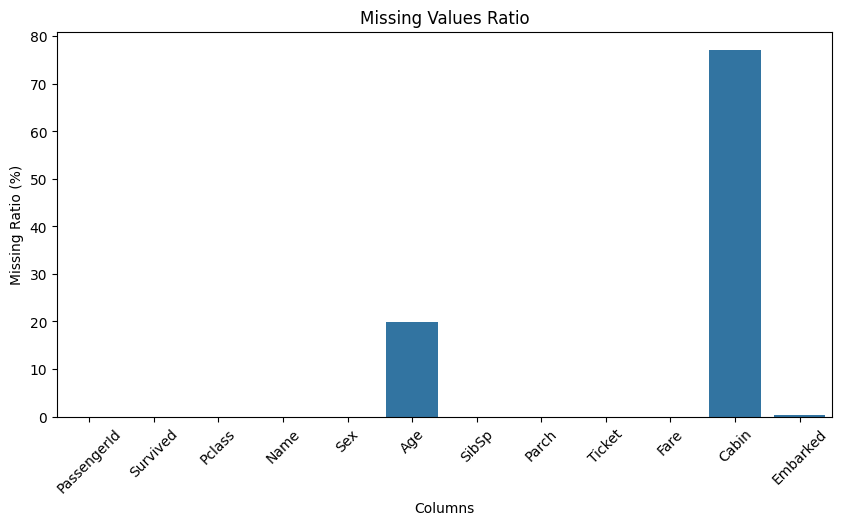

In [9]:
# 결측치 비율 시각화

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_data.index,
    y=missing_data['결측치 비율(%)']
)

plt.title('Missing Values Ratio')
plt.xlabel('Columns')
plt.ylabel('Missing Ratio (%)')
plt.xticks(rotation=45)

plt.show()

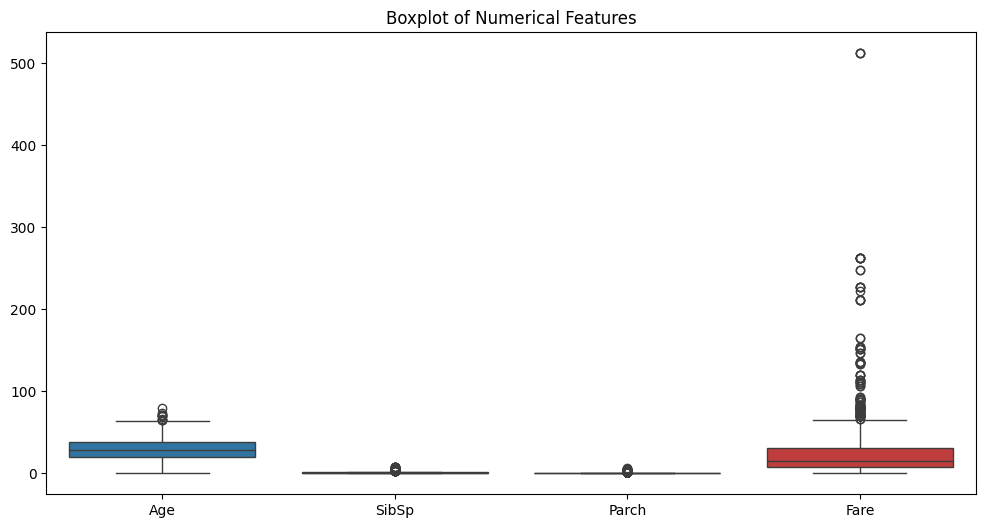

In [10]:
# 수치형 변수 이상치 탐색

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[['Age', 'SibSp', 'Parch', 'Fare']])

plt.title('Boxplot of Numerical Features')
plt.show()

In [11]:
# IQR 방식으로 이상치 개수 확인

cols = ['Age', 'SibSp', 'Parch', 'Fare']

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1

    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    outlier = df[(df[col] < low) | (df[col] > high)]

    print(col, "이상치 개수:", len(outlier))

Age 이상치 개수: 11
SibSp 이상치 개수: 46
Parch 이상치 개수: 213
Fare 이상치 개수: 116


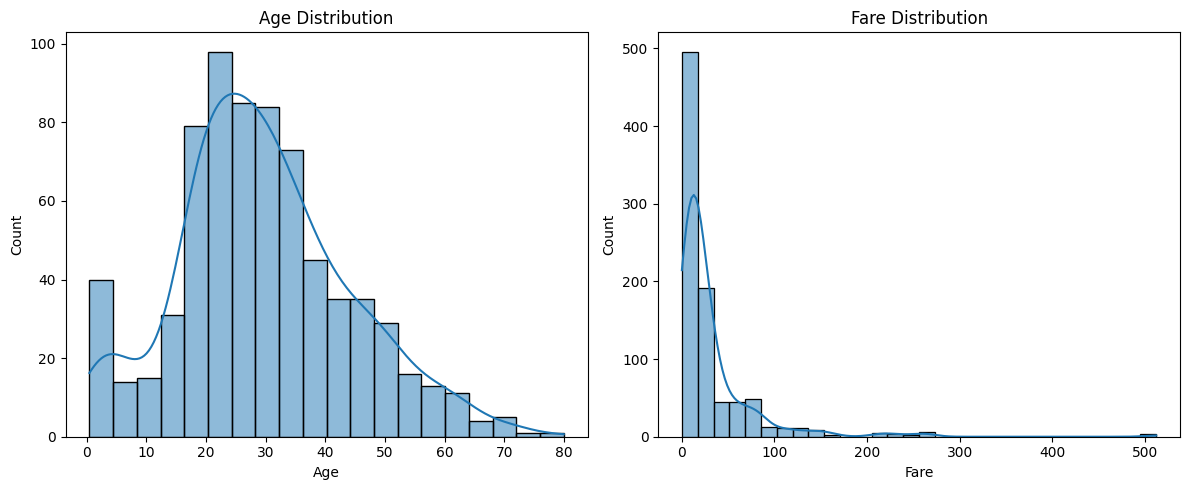

In [12]:
# 수치형 변수의 분포 확인

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Age'].dropna(), bins=20, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')

plt.subplot(1, 2, 2)
sns.histplot(df['Fare'], bins=30, kde=True)
plt.title('Fare Distribution')
plt.xlabel('Fare')

plt.tight_layout()
plt.show()

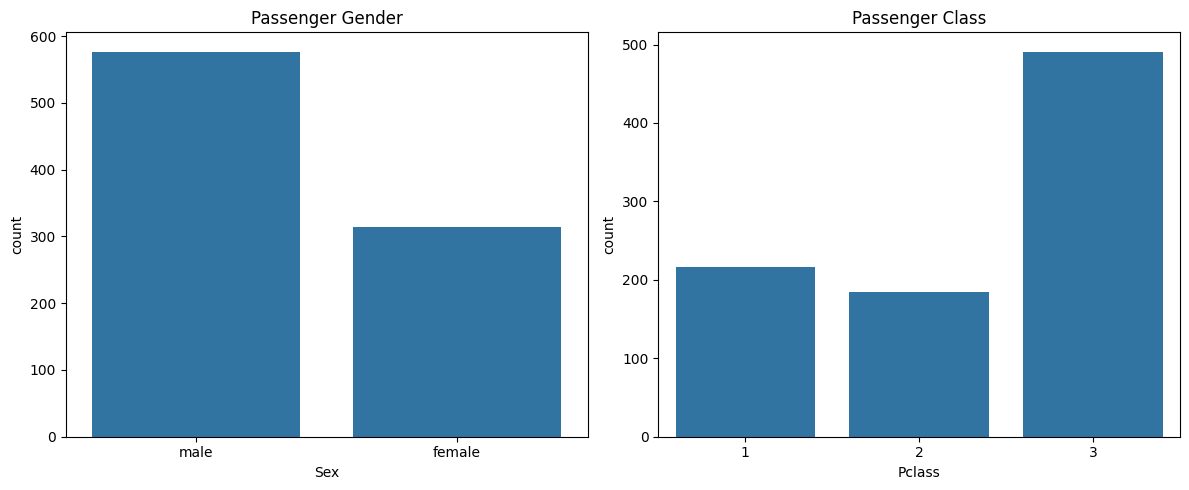

In [13]:
# 범주형 변수 분포 확인

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Sex')
plt.title('Passenger Gender')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Pclass')
plt.title('Passenger Class')

plt.tight_layout()
plt.show()

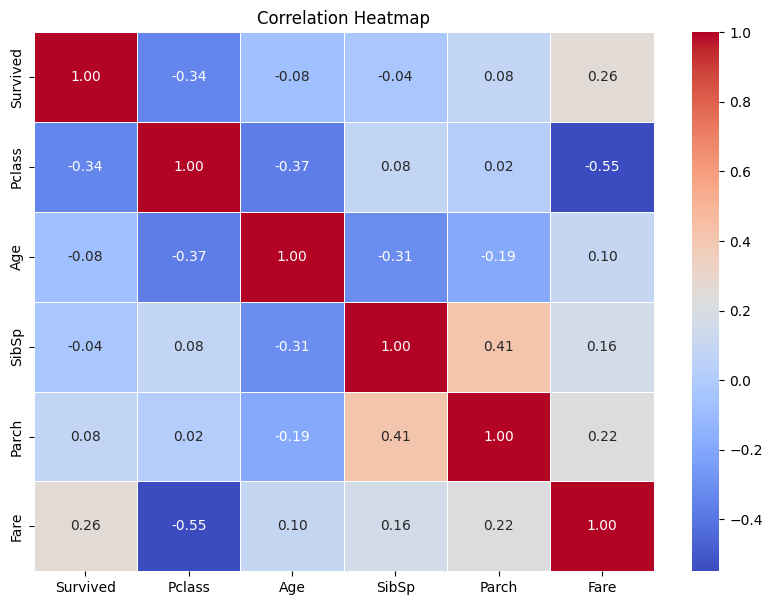

In [14]:
# 수치형 변수 간 상관관계 분석

corr = df[['Survived', 'Pclass', 'Age', 'SibSp',
           'Parch', 'Fare']].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

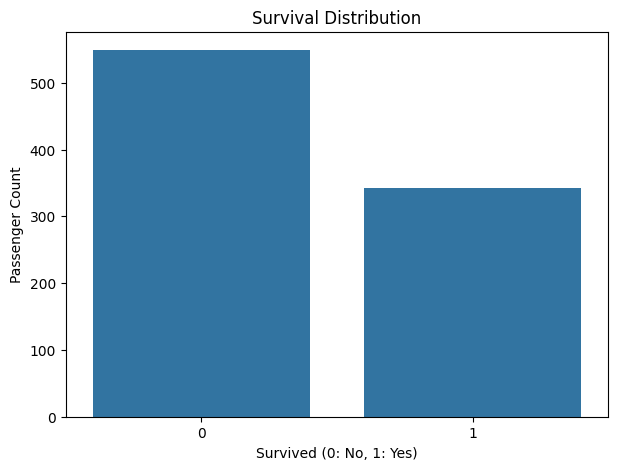

In [15]:
# 생존 여부 분포 시각화

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Survived')

plt.title('Survival Distribution')
plt.xlabel('Survived (0: No, 1: Yes)')
plt.ylabel('Passenger Count')

plt.show()

In [16]:
# 생존자와 사망자 비율 계산

survival_ratio = df['Survived'].value_counts(normalize=True) * 100

print("사망 비율:", round(survival_ratio[0], 2), "%")
print("생존 비율:", round(survival_ratio[1], 2), "%")

사망 비율: 61.62 %
생존 비율: 38.38 %


In [17]:
# 분석에 사용할 변수 선택

X = df[['Pclass', 'Sex', 'Age', 'SibSp',
        'Parch', 'Fare', 'Embarked']].copy()

y = df['Survived']

# 학습 데이터와 테스트 데이터 분리

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

학습 데이터: (712, 7)
테스트 데이터: (179, 7)


In [18]:
# 평균과 중앙값으로 결측치 처리

from sklearn.impute import SimpleImputer

# 평균으로 처리
mean_imputer = SimpleImputer(strategy='mean')

age_mean = mean_imputer.fit_transform(
    X_train[['Age']]
)

# 중앙값으로 처리
median_imputer = SimpleImputer(strategy='median')

age_median = median_imputer.fit_transform(
    X_train[['Age']]
)

print("평균으로 채운 값:", mean_imputer.statistics_[0])
print("중앙값으로 채운 값:", median_imputer.statistics_[0])

평균으로 채운 값: 29.807686956521735
중앙값으로 채운 값: 28.5


In [19]:
# 최빈값으로 결측치 처리

freq_imputer = SimpleImputer(strategy='most_frequent')

embarked_freq = freq_imputer.fit_transform(
    X_train[['Embarked']]
)

print("Embarked 최빈값:", freq_imputer.statistics_[0])

Embarked 최빈값: S


In [20]:
print("평균 처리 후 Age 결측치:",
      np.isnan(age_mean).sum())

print("중앙값 처리 후 Age 결측치:",
      np.isnan(age_median).sum())

print("최빈값 처리 후 Embarked 결측치:",
      pd.isna(embarked_freq).sum())

평균 처리 후 Age 결측치: 0
중앙값 처리 후 Age 결측치: 0
최빈값 처리 후 Embarked 결측치: 0


In [21]:
# Label Encoding

from sklearn.preprocessing import OrdinalEncoder

label_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_label = X_train.copy()
X_test_label = X_test.copy()

# 성별과 탑승 항구를 숫자로 변환
cat_cols = ['Sex', 'Embarked']

X_train_label[cat_cols] = label_encoder.fit_transform(
    X_train[cat_cols]
)

X_test_label[cat_cols] = label_encoder.transform(
    X_test[cat_cols]
)

print("Label Encoding 결과")
display(X_train_label.head())

Label Encoding 결과


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
692,3,1.0,NaN,0,0,56.4958,2.0
481,2,1.0,NaN,0,0,0.0000,2.0
527,1,1.0,NaN,0,0,221.7792,2.0
855,3,0.0,18.0,0,1,9.3500,2.0
801,2,0.0,31.0,1,1,26.2500,2.0


In [22]:
# One-Hot Encoding

X_train_onehot = pd.get_dummies(
    X_train,
    columns=['Sex', 'Embarked'],
    dtype=int
)

X_test_onehot = pd.get_dummies(
    X_test,
    columns=['Sex', 'Embarked'],
    dtype=int
)

# 학습 데이터와 테스트 데이터 컬럼 맞추기
X_test_onehot = X_test_onehot.reindex(
    columns=X_train_onehot.columns,
    fill_value=0
)

print("One-Hot Encoding 결과")
display(X_train_onehot.head())

One-Hot Encoding 결과


,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,3,NaN,0,0,56.4958,0,1,0,0,1
481,2,NaN,0,0,0.0000,0,1,0,0,1
527,1,NaN,0,0,221.7792,0,1,0,0,1
855,3,18.0,0,1,9.3500,1,0,0,0,1
801,2,31.0,1,1,26.2500,1,0,0,0,1


In [23]:
# 인코딩 결과 비교

print("원본 컬럼 개수:", X_train.shape[1])

print("Label Encoding 컬럼 개수:",
      X_train_label.shape[1])

print("One-Hot Encoding 컬럼 개수:",
      X_train_onehot.shape[1])

print("\nOne-Hot Encoding 컬럼 목록:")
print(X_train_onehot.columns.tolist())

원본 컬럼 개수: 7
Label Encoding 컬럼 개수: 7
One-Hot Encoding 컬럼 개수: 10

One-Hot Encoding 컬럼 목록:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler

# 스케일링할 수치형 변수 선택

num_cols = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

# StandardScaler
standard_scaler = StandardScaler()

X_standard = X_train[num_cols].copy()

X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_standard),
    columns=num_cols
)

# MinMaxScaler
minmax_scaler = MinMaxScaler()

X_minmax = X_train[num_cols].copy()

X_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X_minmax),
    columns=num_cols
)

# RobustScaler
robust_scaler = RobustScaler()

X_robust = X_train[num_cols].copy()

X_robust = pd.DataFrame(
    robust_scaler.fit_transform(X_robust),
    columns=num_cols
)

print("스케일링 끝")

스케일링 끝


In [27]:
# 스케일링 결과 비교

print("원본 데이터")
display(X_train[num_cols].head())

print("StandardScaler")
display(X_standard.head())

print("MinMaxScaler")
display(X_minmax.head())

print("RobustScaler")
display(X_robust.head())

원본 데이터


,Pclass,Age,SibSp,Parch,Fare
692,3,NaN,0,0,56.4958
481,2,NaN,0,0,0.0000
527,1,NaN,0,0,221.7792
855,3,18.0,0,1,9.3500
801,2,31.0,1,1,26.2500


StandardScaler


,Pclass,Age,SibSp,Parch,Fare
0,0.829568,NaN,-0.465084,-0.466183,0.513812
1,-0.370945,NaN,-0.465084,-0.466183,-0.662563
2,-1.571457,NaN,-0.465084,-0.466183,3.955399
3,0.829568,-0.815864,-0.465084,0.727782,-0.467874
4,-0.370945,0.082384,0.478335,0.727782,-0.115977


MinMaxScaler


,Pclass,Age,SibSp,Parch,Fare
0,1.0,NaN,0.000,0.000000,0.110272
1,0.5,NaN,0.000,0.000000,0.000000
2,0.0,NaN,0.000,0.000000,0.432884
3,1.0,0.220910,0.000,0.166667,0.018250
4,0.5,0.384267,0.125,0.166667,0.051237


RobustScaler


,Pclass,Age,SibSp,Parch,Fare
0,0.0,NaN,0.0,0.0,1.819652
1,-1.0,NaN,0.0,0.0,-0.625609
2,-2.0,NaN,0.0,0.0,8.973477
3,0.0,-0.583333,0.0,1.0,-0.220921
4,-1.0,0.138889,1.0,1.0,0.510548


In [28]:
# 스케일링 결과의 최소값과 최대값 비교

result = pd.DataFrame({
    'Standard 최소값': X_standard.min(),
    'Standard 최대값': X_standard.max(),
    'MinMax 최소값': X_minmax.min(),
    'MinMax 최대값': X_minmax.max(),
    'Robust 최소값': X_robust.min(),
    'Robust 최대값': X_robust.max()
})

display(result)

,Standard 최소값,Standard 최대값,MinMax 최소값,MinMax 최대값,Robust 최소값,Robust 최대값
Pclass,-1.571457,0.829568,0.0,1.0,-2.000000,0.000000
Age,-2.030573,3.468090,0.0,1.0,-1.560000,2.861111
SibSp,-0.465084,7.082266,0.0,1.0,0.000000,8.000000
Parch,-0.466183,6.697610,0.0,1.0,0.000000,6.000000
Fare,-0.662563,10.005329,0.0,1.0,-0.625609,21.549112


In [29]:
# 파생 변수 생성

df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

df['FarePerPerson'] = df['Fare'] / df['FamilySize']

df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

print("파생 변수 생성 완료!")

display(df[['SibSp', 'Parch', 'Fare',
            'FamilySize', 'FarePerPerson',
            'IsAlone']].head(10))

파생 변수 생성 완료!


,SibSp,Parch,Fare,FamilySize,FarePerPerson,IsAlone
0,1,0,7.2500,2,3.62500,0
1,1,0,71.2833,2,35.64165,0
2,0,0,7.9250,1,7.92500,1
3,1,0,53.1000,2,26.55000,0
4,0,0,8.0500,1,8.05000,1
5,0,0,8.4583,1,8.45830,1
6,0,0,51.8625,1,51.86250,1
7,3,1,21.0750,5,4.21500,0
8,0,2,11.1333,3,3.71110,0
9,1,0,30.0708,2,15.03540,0


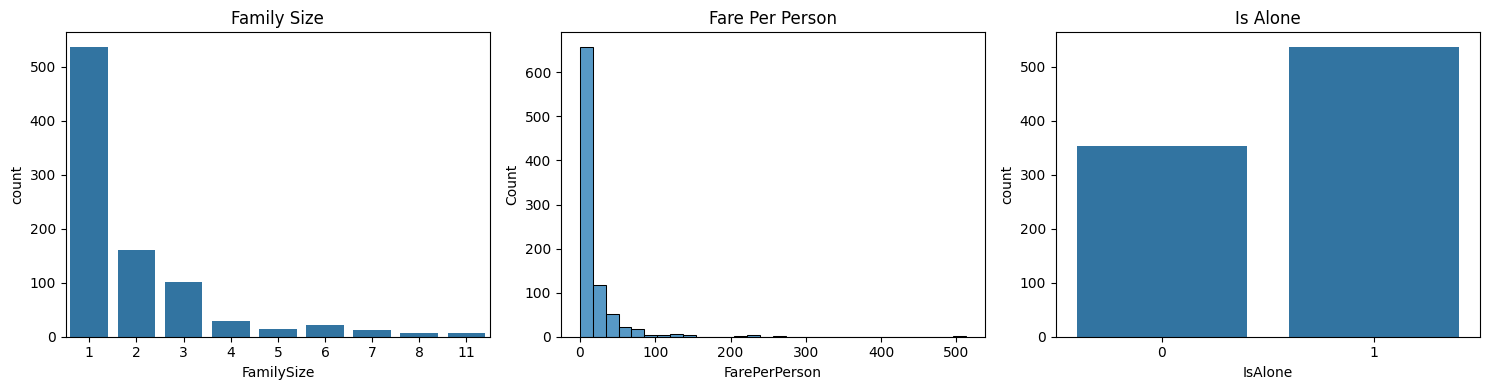

In [30]:
# 파생 변수 시각화

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.countplot(data=df, x='FamilySize')
plt.title('Family Size')

plt.subplot(1, 3, 2)
sns.histplot(df['FarePerPerson'], bins=30)
plt.title('Fare Per Person')

plt.subplot(1, 3, 3)
sns.countplot(data=df, x='IsAlone')
plt.title('Is Alone')

plt.tight_layout()
plt.show()

In [31]:
# 파생 변수를 포함한 데이터 구성

from sklearn.model_selection import train_test_split

features = [
    'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
    'Fare', 'Embarked', 'FamilySize',
    'FarePerPerson', 'IsAlone'
]

X = df[features].copy()
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

학습 데이터: (712, 10)
테스트 데이터: (179, 10)


In [33]:
# 필요한 라이브러리

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# 수치형 및 범주형 변수 구분
num_cols = [
    'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'FamilySize', 'FarePerPerson', 'IsAlone'
]

cat_cols = ['Sex', 'Embarked']

# 수치형 데이터 처리
num_process = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# 범주형 데이터 처리
cat_process = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 전체 전처리
preprocessor = ColumnTransformer([
    ('num', num_process, num_cols),
    ('cat', cat_process, cat_cols)
])

# 전처리 실행
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Random Forest 학습
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_processed, y_train)

print("Random Forest 학습 완료")

Random Forest 학습 완료


In [34]:
# 변수 중요도 계산

importances = rf.feature_importances_

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(importance_df)

,Feature,Importance
1,num__Age,0.212696
6,num__FarePerPerson,0.174838
4,num__Fare,0.153321
9,cat__Sex_male,0.144828
8,cat__Sex_female,0.125761
0,num__Pclass,0.065702
5,num__FamilySize,0.036285
2,num__SibSp,0.022209
3,num__Parch,0.020760
12,cat__Embarked_S,0.016668


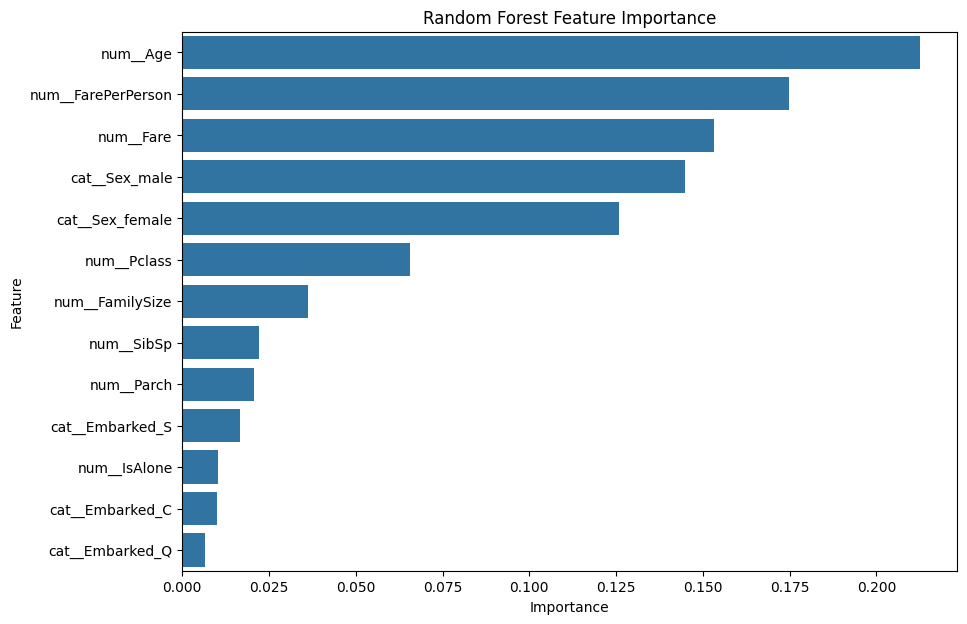

In [35]:
# 변수 중요도 그래프

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.show()

In [36]:
# 중요도 상위 10개 변수 선택

top_features = importance_df.head(10)['Feature'].tolist()

print("선택된 상위 10개 변수:")
for feature in top_features:
    print(feature)

선택된 상위 10개 변수:
num__Age
num__FarePerPerson
num__Fare
cat__Sex_male
cat__Sex_female
num__Pclass
num__FamilySize
num__SibSp
num__Parch
cat__Embarked_S


In [37]:
# 변수 선택 전후 성능 비교

from sklearn.metrics import accuracy_score, f1_score

# 전체 변수 사용
pred_all = rf.predict(X_test_processed)

# 상위 10개 변수만 사용
top_indices = [
    list(feature_names).index(feature)
    for feature in top_features
]

X_train_selected = X_train_processed[:, top_indices]
X_test_selected = X_test_processed[:, top_indices]

rf_selected = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_selected.fit(X_train_selected, y_train)

pred_selected = rf_selected.predict(X_test_selected)

# 성능 비교표
result = pd.DataFrame({
    '모델': ['전체 변수', '상위 10개 변수'],
    'Accuracy': [
        accuracy_score(y_test, pred_all),
        accuracy_score(y_test, pred_selected)
    ],
    'F1-score': [
        f1_score(y_test, pred_all),
        f1_score(y_test, pred_selected)
    ]
})

display(result)

,모델,Accuracy,F1-score
0,전체 변수,0.815642,0.751880
1,상위 10개 변수,0.810056,0.746269


In [38]:
# 필요한 라이브러리 불러오기

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 수치형과 범주형 변수 구분

num_cols = [
    'Pclass', 'Age', 'SibSp', 'Parch',
    'Fare', 'FamilySize', 'FarePerPerson', 'IsAlone'
]

cat_cols = ['Sex', 'Embarked']

# 수치형 전처리
num_process = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 범주형 전처리
cat_process = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 전체 전처리 파이프라인
preprocessor = ColumnTransformer([
    ('num', num_process, num_cols),
    ('cat', cat_process, cat_cols)
])

print("전처리 파이프라인 준비 완료!")

전처리 파이프라인 준비 완료!


In [39]:
# Logistic Regression 모델 생성

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

# 모델 학습
lr_model.fit(X_train, y_train)

print("Logistic Regression 학습 완료!")

Logistic Regression 학습 완료!


In [40]:
# Random Forest 모델 생성

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# 모델 학습
rf_model.fit(X_train, y_train)

print("Random Forest 학습 완료!")

Random Forest 학습 완료!


In [41]:
# 예측 결과 생성

lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

lr_prob = lr_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# 성능 평가 함수
def evaluate_model(name, y_true, pred, prob):

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred),
        'Recall': recall_score(y_true, pred),
        'F1-score': f1_score(y_true, pred),
        'ROC-AUC': roc_auc_score(y_true, prob)
    }

# 성능 비교표 작성
results = pd.DataFrame([
    evaluate_model('Logistic Regression', y_test, lr_pred, lr_prob),
    evaluate_model('Random Forest', y_test, rf_pred, rf_prob)
])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8507
1,Random Forest,0.8045,0.7742,0.6957,0.7328,0.8144


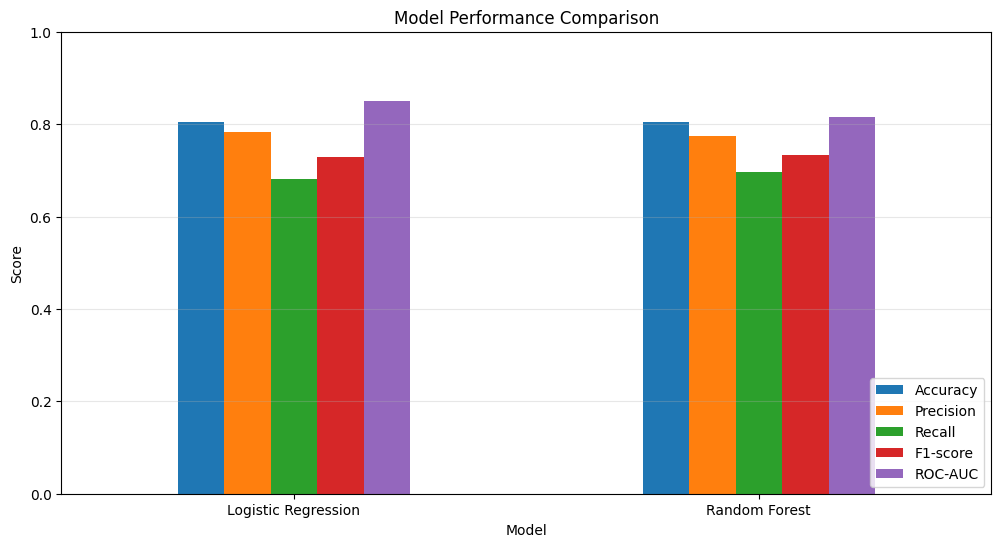

In [42]:
# 모델별 성능 비교 그래프

results_plot = results.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 사용할 컬럼
num_cols = [
    'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
    'FamilySize', 'FarePerPerson', 'IsAlone'
]
cat_cols = ['Sex', 'Embarked']

# 실험별 전처리 설정
experiments = {
    'Base': {
        'imputer': 'median',
        'encoding': 'onehot',
        'scaling': None,
        'selection': False
    },
    'Exp-1': {
        'imputer': 'mean',
        'encoding': 'onehot',
        'scaling': 'standard',
        'selection': False
    },
    'Exp-2': {
        'imputer': 'median',
        'encoding': 'label',
        'scaling': 'minmax',
        'selection': True
    },
    'Exp-3': {
        'imputer': 'most_frequent',
        'encoding': 'onehot',
        'scaling': 'robust',
        'selection': True
    }
}

# 전처리 파이프라인 생성 함수
def make_preprocessor(setting):
    num_steps = [
        ('imputer', SimpleImputer(strategy=setting['imputer']))
    ]

    if setting['scaling'] == 'standard':
        num_steps.append(('scaler', StandardScaler()))
    elif setting['scaling'] == 'minmax':
        num_steps.append(('scaler', MinMaxScaler()))
    elif setting['scaling'] == 'robust':
        num_steps.append(('scaler', RobustScaler()))

    if setting['encoding'] == 'onehot':
        encoder = OneHotEncoder(handle_unknown='ignore')
    else:
        encoder = OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        )

    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', encoder)
    ])

    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', cat_pipe, cat_cols)
    ])

# 실험 및 모델 평가
results_all = []
experiment_models = {}

for exp_name, setting in experiments.items():

    for model_name in ['Logistic Regression', 'Random Forest']:

        steps = [
            ('preprocessor', make_preprocessor(setting))
        ]

        if setting['selection']:
            steps.append(('selection', SelectKBest(score_func=f_classif, k=8)))

        if model_name == 'Logistic Regression':
            model = LogisticRegression(max_iter=1000)
        else:
            model = RandomForestClassifier(
                n_estimators=100,
                random_state=42
            )

        steps.append(('model', model))

        pipe = Pipeline(steps)
        pipe.fit(X_train, y_train)

        # 실험별 학습 모델 저장
        if exp_name not in experiment_models:
            experiment_models[exp_name] = {}
        experiment_models[exp_name][model_name] = pipe

        pred = pipe.predict(X_test)
        prob = pipe.predict_proba(X_test)[:, 1]

        results_all.append({
            'Experiment': exp_name,
            'Model': model_name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1-score': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob)
        })

# 결과표 출력
results_all = pd.DataFrame(results_all)

print("실험별 모델 성능 비교")
display(results_all.round(4))

실험별 모델 성능 비교


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Base,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8501
1,Base,Random Forest,0.8156,0.7812,0.7246,0.7519,0.8182
2,Exp-1,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8499
3,Exp-1,Random Forest,0.8101,0.7612,0.7391,0.7500,0.8184
4,Exp-2,Logistic Regression,0.7765,0.7231,0.6812,0.7015,0.8403
5,Exp-2,Random Forest,0.7821,0.7344,0.6812,0.7068,0.8104
6,Exp-3,Logistic Regression,0.7821,0.7344,0.6812,0.7068,0.8239
7,Exp-3,Random Forest,0.7821,0.7273,0.6957,0.7111,0.8050


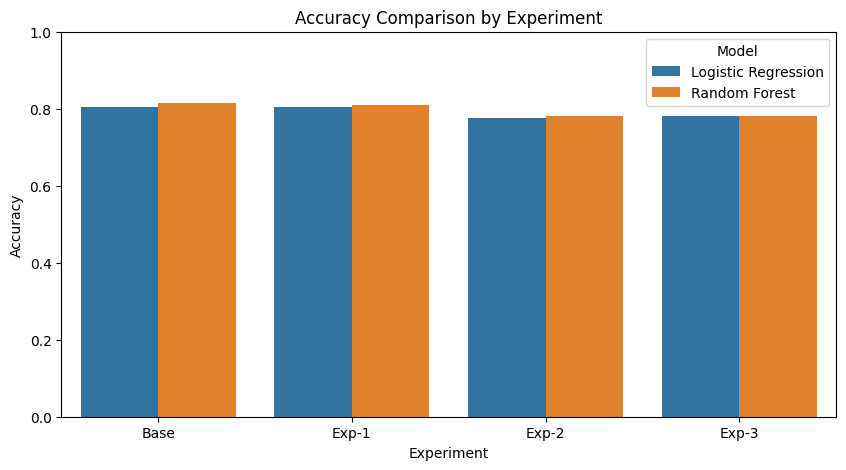

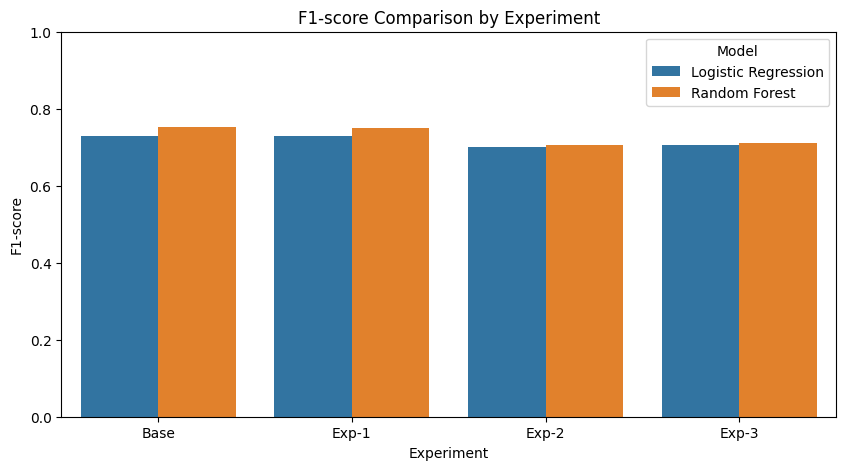

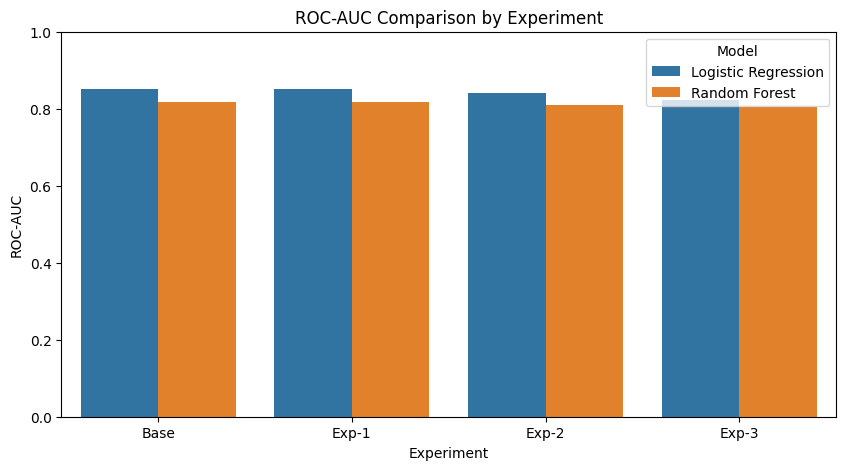

In [44]:
# 실험별 Accuracy 비교
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_all,
    x='Experiment',
    y='Accuracy',
    hue='Model'
)

plt.title('Accuracy Comparison by Experiment')
plt.ylim(0, 1)
plt.show()


# 실험별 F1-score 비교
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_all,
    x='Experiment',
    y='F1-score',
    hue='Model'
)

plt.title('F1-score Comparison by Experiment')
plt.ylim(0, 1)
plt.show()


# 실험별 ROC-AUC 비교
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_all,
    x='Experiment',
    y='ROC-AUC',
    hue='Model'
)

plt.title('ROC-AUC Comparison by Experiment')
plt.ylim(0, 1)
plt.show()

In [45]:
# 전체 실험 결과 정리
print("최종 실험 결과")
display(results_all.round(4))

# F1-score 기준 최고 성능 모델
best_model = results_all.loc[results_all['F1-score'].idxmax()]

print("\nF1-score 기준 최고 성능")
print("실험:", best_model['Experiment'])
print("모델:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1-score:", round(best_model['F1-score'], 4))
print("ROC-AUC:", round(best_model['ROC-AUC'], 4))

최종 실험 결과


,Experiment,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Base,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8501
1,Base,Random Forest,0.8156,0.7812,0.7246,0.7519,0.8182
2,Exp-1,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8499
3,Exp-1,Random Forest,0.8101,0.7612,0.7391,0.7500,0.8184
4,Exp-2,Logistic Regression,0.7765,0.7231,0.6812,0.7015,0.8403
5,Exp-2,Random Forest,0.7821,0.7344,0.6812,0.7068,0.8104
6,Exp-3,Logistic Regression,0.7821,0.7344,0.6812,0.7068,0.8239
7,Exp-3,Random Forest,0.7821,0.7273,0.6957,0.7111,0.8050



F1-score 기준 최고 성능
실험: Base
모델: Random Forest
Accuracy: 0.8156
Precision: 0.7812
Recall: 0.7246
F1-score: 0.7519
ROC-AUC: 0.8182


In [ ]:
from sklearn.model_selection import GridSearchCV

# Base Random Forest의 탐색 범위
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 5, 10],
    'model__min_samples_split': [2, 5]
}

# Base 실험의 Random Forest를 대상으로 GridSearchCV 설정
grid_search = GridSearchCV(
    estimator=experiment_models['Base']['Random Forest'],
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

# 학습 및 최적 설정 탐색
grid_search.fit(X_train, y_train)

# 최적 파라미터 출력
print("최적 파라미터:")
print(grid_search.best_params_)

print("\n교차검증 최고 F1-score:")
print(round(grid_search.best_score_, 4))

# 최적 모델의 테스트 데이터 성능
best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test)
best_prob = best_rf.predict_proba(X_test)[:, 1]

print("\n최적 모델 테스트 성능")
print("Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("Precision:", round(precision_score(y_test, best_pred), 4))
print("Recall:", round(recall_score(y_test, best_pred), 4))
print("F1-score:", round(f1_score(y_test, best_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_prob), 4))

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

# Base 실험 모델과 튜닝 모델의 예측값
base_rf_model = experiment_models['Base']['Random Forest']
base_pred = base_rf_model.predict(X_test)
best_pred = best_rf.predict(X_test)

# Confusion Matrix 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, base_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Base Random Forest')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(
    confusion_matrix(y_test, best_pred),
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)
axes[1].set_title('Tuned Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Classification Report
print("Base Experiment Random Forest")
print(classification_report(y_test, base_pred))

print("Tuned Random Forest")
print(classification_report(y_test, best_pred))